# Análise NPS - Desafio Fase 1


In [19]:
# Import das bibliotecas que serão utilizadas
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [20]:
# Leitura inicial do meu arquivo
nps = pd.read_csv("desafio_nps_fase_1.csv")
nps.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [21]:
print(f'Tamanho do meu dataset (Linhas, Colunas): {nps.shape}')

Tamanho do meu dataset (Linhas, Colunas): (2500, 19)


In [22]:
print(f'Quantidade de dados nulos no meu dataset: {nps.isnull().sum().sum()}')

Quantidade de dados nulos no meu dataset: 0


In [23]:
# Visão geral da base
display(nps.describe())
print(nps.isna().sum())

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
count,2500.00000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,43.396000,61.322400,51250.50000,434.259740,3.470800,29.745620,6.004000,8.022000,2.187200,38.217016,2.005600,1.519600,5.485600,4.378600,0.087200,4.150400,2.941600
std,721.83216,14.888487,34.478729,721.83216,289.772497,1.687331,29.225603,3.159743,3.770411,1.454442,12.076074,0.815497,1.231512,3.458002,2.510229,0.282184,1.784223,2.378957
min,1.00000,18.000000,1.000000,50001.00000,7.760000,1.000000,0.020000,1.000000,2.000000,0.000000,2.620000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,625.75000,31.000000,31.000000,50625.75000,220.245000,2.000000,8.885000,3.000000,5.000000,1.000000,29.927500,1.000000,1.000000,2.000000,2.600000,0.000000,3.000000,0.700000
50%,1250.50000,43.000000,62.000000,51250.50000,375.515000,3.000000,20.935000,6.000000,8.000000,2.000000,38.500000,2.000000,1.000000,6.000000,4.400000,0.000000,4.000000,2.800000
75%,1875.25000,56.000000,91.000000,51875.25000,577.290000,5.000000,40.832500,9.000000,11.000000,3.000000,46.270000,3.000000,2.000000,8.000000,6.100000,0.000000,5.000000,4.800000
max,2500.00000,69.000000,119.000000,52500.00000,1983.810000,6.000000,230.330000,11.000000,14.000000,8.000000,76.130000,3.000000,7.000000,11.000000,10.000000,1.000000,11.000000,10.000000


customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64


In [24]:
# Cálculo percentual do NPS
promotores=(nps.nps_score>=9).mean()*100
neutros=((nps.nps_score>=7)&(nps.nps_score<=8)).mean()*100
detratores=(nps.nps_score<=6).mean()*100
nps_final=promotores-detratores
print(f"NPS: {nps_final:.1f}")
print(f"Promotores: {promotores:.1f}%")
print(f"Neutros: {neutros:.1f}%")
print(f"Detratores: {detratores:.1f}%")

NPS: -69.6
Promotores: 4.4%
Neutros: 7.6%
Detratores: 74.0%


In [25]:
# Além das avaliações, como está a Recompra?
repeat_rate=nps.repeat_purchase_30d.mean()*100
print(f"Taxa de recompra: {repeat_rate:.1f}%")

Taxa de recompra: 8.7%


1) A recompra está baixa. Posso até ter uma avaliação boa mas o cliente não está retornando com uma frequência boa para o ecommerce

customer_region
Centro-Oeste    4.209829
Sudeste         4.373846
Norte           4.382609
Nordeste        4.421649
Sul             4.490979
Name: nps_score, dtype: float64


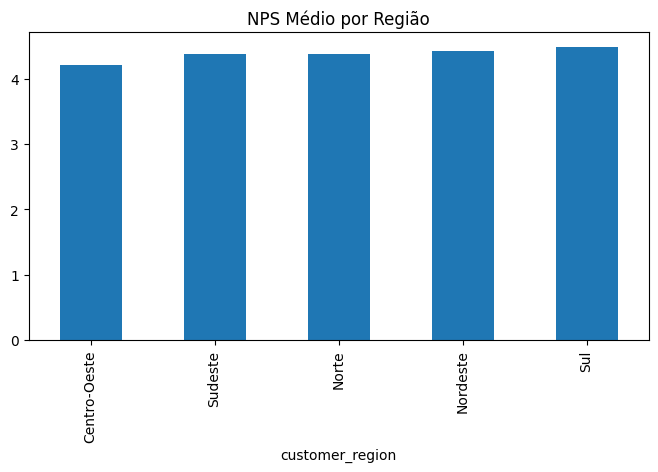

In [26]:
# Há alguma região mais ofensora de NPS ?
region=nps.groupby("customer_region")["nps_score"].mean().sort_values()
print(region)
region.plot(kind="bar",figsize=(8,4),title="NPS Médio por Região")
plt.show()

2) Não há nenhuma região que se destaque, está bem disbrituida a médina de NPS

delivery_delay_days         -0.597260
complaints_count            -0.496800
customer_service_contacts   -0.350845
resolution_time_days        -0.191392
freight_value               -0.041087
customer_age                -0.009936
customer_tenure_months      -0.009711
delivery_time_days           0.000925
items_quantity               0.011468
customer_id                  0.015162
order_id                     0.015162
payment_installments         0.023718
discount_value               0.025104
delivery_attempts            0.027680
order_value                  0.036990
csat_internal_score          0.563952
repeat_purchase_30d          0.570324
nps_score                    1.000000
Name: nps_score, dtype: float64


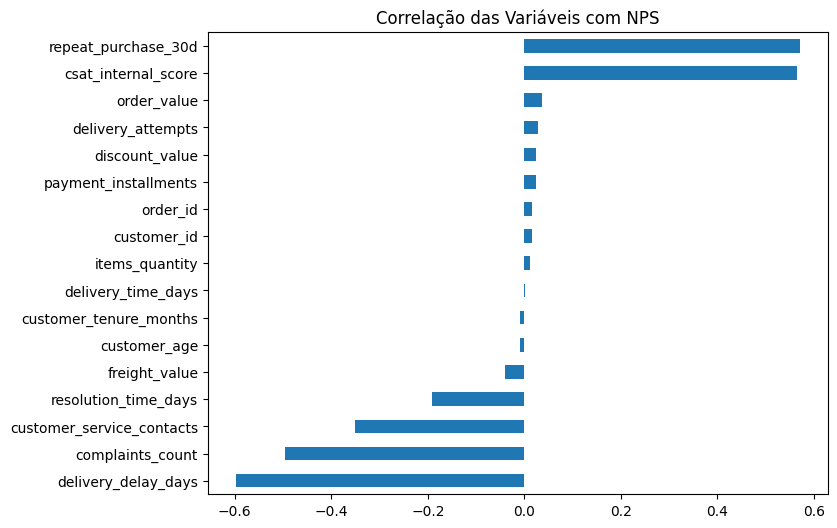

In [27]:
# Avaliando Correlações com NPS
corr=nps.corr(numeric_only=True)["nps_score"].sort_values()
print(corr)
plt.figure(figsize=(8,6))
corr.drop("nps_score").plot(kind="barh")
plt.title("Correlação das Variáveis com NPS")
plt.show()

3) Analise da correlação
- delivery_delay_days: Quanto mais atraso, menor o NPS
- complaints_count: Quanto mais reclamações, menor o NPS
- customer_service_contacts: Quanto mais contato com suporte, menor o NPS
- resolution_time_days: Quanto mais demora para resolver, menor o NPS

Resumo: A grande relação de atraso logisto e pós venda sem eficiência com a má avaliação do ecommerce no NPS.

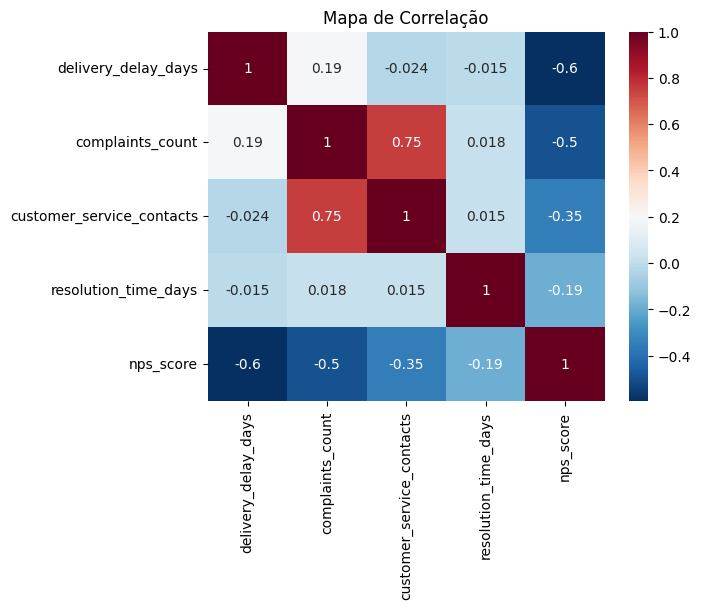

In [28]:
# Principais fatores críticos
cols=["delivery_delay_days","complaints_count","customer_service_contacts","resolution_time_days","nps_score"]
sns.heatmap(nps[cols].corr(),annot=True,cmap="RdBu_r")
plt.title("Mapa de Correlação")
plt.show()

In [29]:
# Busca por pontos de ruptura
for c in ["delivery_delay_days","customer_service_contacts","complaints_count"]:
    print(f"\n=== {c} ===")
    print(nps.groupby(c)["nps_score"].mean().head(20))


=== delivery_delay_days ===
delivery_delay_days
0    6.856679
1    5.546179
2    4.580186
3    3.436762
4    2.444444
5    1.481034
6    1.097059
7    0.292857
8    0.000000
Name: nps_score, dtype: float64

=== customer_service_contacts ===
customer_service_contacts
0    5.543502
1    4.657108
2    4.116406
3    3.201911
4    2.654545
5    2.238235
6    0.742857
7    1.200000
Name: nps_score, dtype: float64

=== complaints_count ===
complaints_count
0     8.517391
1     7.770492
2     6.052347
3     4.910059
4     4.219167
5     3.645270
6     3.062030
7     2.813609
8     2.065079
9     2.487500
10    2.281818
11    0.850000
Name: nps_score, dtype: float64


<Axes: xlabel='customer_service_contacts', ylabel='delivery_delay_days'>

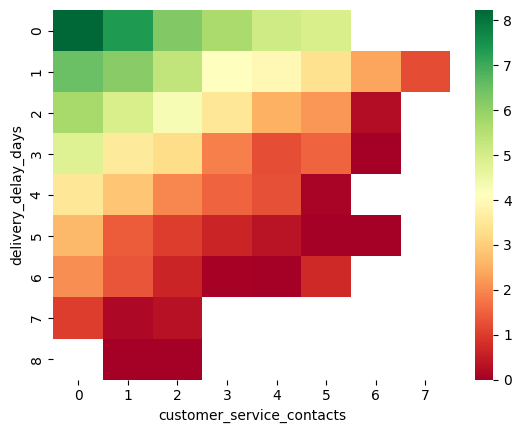

In [30]:
# Avaliandos combinações mais nossivas para a experiência do cliente
pivot = pd.pivot_table(
    nps,
    values="nps_score",
    index="delivery_delay_days",
    columns="customer_service_contacts",
    aggfunc="mean"
)

sns.heatmap(pivot, cmap="RdYlGn")

<Axes: xlabel='complaints_count', ylabel='delivery_delay_days'>

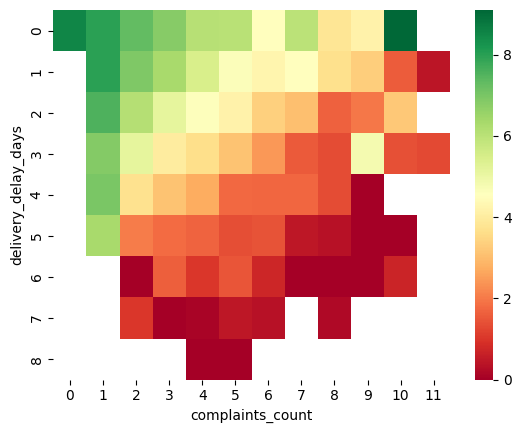

In [31]:
pivot = pd.pivot_table(
    nps,
    values="nps_score",
    index="delivery_delay_days",
    columns="complaints_count",
    aggfunc="mean"
)

sns.heatmap(pivot, cmap="RdYlGn")

In [32]:
# Combinações e riscos

# Atraso a partir de 3 dias
nps["risco_atraso"] = (nps["delivery_delay_days"] >= 3).astype(int)

# A partir de 2 contatos
nps["risco_contatos"] = (nps["customer_service_contacts"] >= 2).astype(int)

# A partir de 4 reclamações
nps["risco_reclamacoes"] = (nps["complaints_count"] >= 4).astype(int)

nps["risco_combinacoes"] = (
    nps["risco_atraso"].astype(str)
    + nps["risco_contatos"].astype(str)
    + nps["risco_reclamacoes"].astype(str)
)

In [33]:
analise_risco = (
    nps.groupby("risco_combinacoes")
      .agg(
          clientes=("customer_id", "count"),
          nps_medio=("nps_score", "mean"),
          recompra=("repeat_purchase_30d", "mean")
      )
      .reset_index()
)

analise_risco["recompra"] *= 100

analise_risco.sort_values("nps_medio")

,risco_combinacoes,clientes,nps_medio,recompra
7,111,409,1.934474,0.000000
5,101,261,3.036398,0.766284
4,100,288,3.706597,1.736111
3,011,641,4.256474,4.056162
1,001,260,5.094615,8.846154
0,000,561,6.571658,25.668449
6,110,4,6.575000,0.000000
2,010,76,6.964474,23.684211


4) Resultado da analise das combinações de cenários.

Combinações:
111 = atraso + múltiplos contatos + reclamações
101 = atraso + reclamações
001 = apenas reclamações
000 = nenhuma ruptura

Se observarmos as combinações, o atraso é o que possui maior impacto. Se olharmos o cenario 000 sem ruptura e o o 100 que só possui atraso, o NPS cai de 6,57 para 3,71

## Conclusões
- Atraso de entrega é o principal motivo de insatisfação

- Não há problemas de marketing, região, preço, o problema está na execução operacional da jornada pós-venda

- Clientes satisfeitos tendem a recomprar mais

Sem rupturas (000)
NPS = 6,57
Recompra = 25,7%

Apenas atraso (100)
NPS = 3,71
Recompra = 1,7%
